In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("Besant_Student_Pass_Prediction.csv")
df=pd.DataFrame(data)
print(df.head())


   Study_Hours_Per_Day  Attendance_Percentage  Previous_Exam_Score  \
0                  5.8                     82                   47   
1                  8.1                     91                   70   
2                  7.1                     72                   39   
3                  2.4                     83                   38   
4                  3.1                     61                   87   

   Assignments_Completed  Passed  
0                     10       1  
1                      3       1  
2                      9       1  
3                     10       0  
4                      6       0  


In [3]:
print(df.shape)

(200, 5)


In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Study_Hours_Per_Day    200 non-null    float64
 1   Attendance_Percentage  200 non-null    int64  
 2   Previous_Exam_Score    200 non-null    int64  
 3   Assignments_Completed  200 non-null    int64  
 4   Passed                 200 non-null    int64  
dtypes: float64(1), int64(4)
memory usage: 7.9 KB
None


In [5]:
print(df.describe())

       Study_Hours_Per_Day  Attendance_Percentage  Previous_Exam_Score  \
count           200.000000             200.000000           200.000000   
mean              4.772500              75.440000            60.995000   
std               2.487556              14.219613            21.278365   
min               0.500000              50.000000            26.000000   
25%               2.600000              62.750000            42.000000   
50%               4.900000              77.000000            59.500000   
75%               6.925000              88.000000            80.250000   
max               9.000000             100.000000            95.000000   

       Assignments_Completed      Passed  
count             200.000000  200.000000  
mean                5.090000    0.540000  
std                 3.078847    0.499648  
min                 0.000000    0.000000  
25%                 3.000000    0.000000  
50%                 5.000000    1.000000  
75%                 8.000000    

In [6]:
print(df.isnull().sum())

Study_Hours_Per_Day      0
Attendance_Percentage    0
Previous_Exam_Score      0
Assignments_Completed    0
Passed                   0
dtype: int64


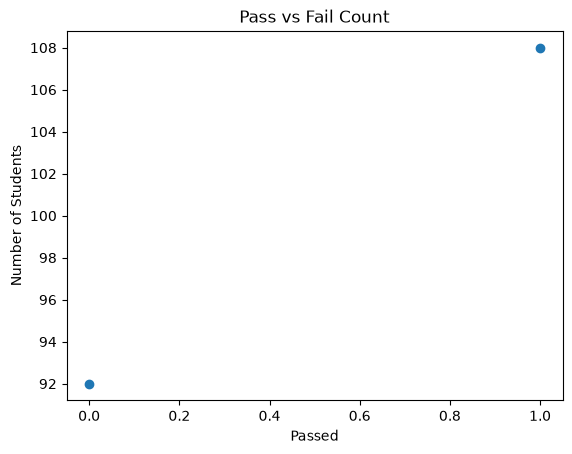

In [7]:
result_counts = df['Passed'].value_counts()

plt.scatter(result_counts.index, result_counts.values)

plt.title('Pass vs Fail Count')
plt.xlabel('Passed')
plt.ylabel('Number of Students')
plt.show()

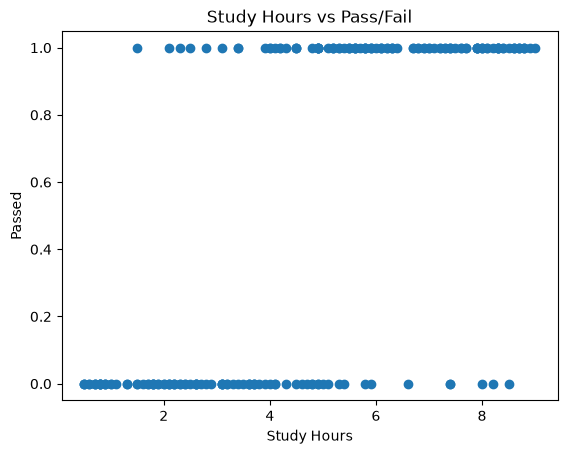

In [8]:
plt.scatter(df['Study_Hours_Per_Day'], df['Passed'])

plt.title('Study Hours vs Pass/Fail')
plt.xlabel('Study Hours')
plt.ylabel('Passed')
plt.show()

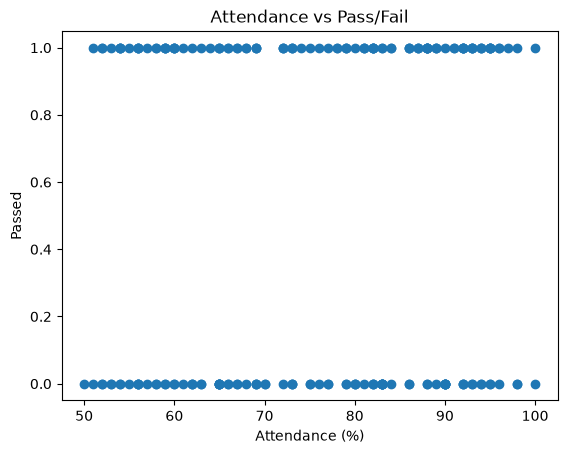

In [9]:
plt.scatter(df['Attendance_Percentage'], df['Passed'])

plt.title('Attendance vs Pass/Fail')
plt.xlabel('Attendance (%)')
plt.ylabel('Passed')
plt.show()

In [10]:
X=df[["Study_Hours_Per_Day" , "Attendance_Percentage","Previous_Exam_Score","Assignments_Completed"]]
print(X.head())

   Study_Hours_Per_Day  Attendance_Percentage  Previous_Exam_Score  \
0                  5.8                     82                   47   
1                  8.1                     91                   70   
2                  7.1                     72                   39   
3                  2.4                     83                   38   
4                  3.1                     61                   87   

   Assignments_Completed  
0                     10  
1                      3  
2                      9  
3                     10  
4                      6  


In [11]:
y=df["Passed"]
print(y.head())

0    1
1    1
2    1
3    0
4    0
Name: Passed, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(

X,
y,
test_size=0.2,
random_state=42,
stratify=y
)

In [13]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [14]:
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [15]:
y_pred = model.predict(X_test)
print(y_pred)

[0 1 1 0 0 0 1 0 1 1 1 0 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 1 0 0 1 0 1 0 0 1 0
 0 1 1]


In [18]:
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
classification_report,
precision_score,
recall_score,
f1_score
)
print("Accuracy", accuracy_score(y_test, y_pred))
print("Precision", precision_score(y_test, y_pred))
print("Recall", recall_score(y_test, y_pred))
print("F1 Score", f1_score(y_test, y_pred))
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy 0.825
Precision 0.8571428571428571
Recall 0.8181818181818182
F1 Score 0.8372093023255814
Confusion Matrix
[[15  3]
 [ 4 18]]
              precision    recall  f1-score   support

           0       0.79      0.83      0.81        18
           1       0.86      0.82      0.84        22

    accuracy                           0.82        40
   macro avg       0.82      0.83      0.82        40
weighted avg       0.83      0.82      0.83        40



In [19]:
import pickle
with open("student_model.pkl", "wb") as file:
    pickle.dump(model, file)